In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 258.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 395.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 359.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 344.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 389.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 348.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 318.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 414.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 303.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 303.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 291.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import re
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import confusion_matrix
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

2025-12-21 10:55:01.056252: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766314501.256366      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766314501.312764      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [4]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)
GLOBAL_RESULTS = {}

def clean_text(text):
    return str(text).strip()

def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)

def predict_one(utterance):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
        
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    return re.sub(r'[\s:,\.;\-]+$', '', text)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())
    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
    
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)
    
    return per_label

def plot_confusion_matrix(df, title_suffix=""):
    """Generates and displays a normalized confusion matrix plot."""
    labels = sorted(df["role_norm"].unique())
    
    label_display_map = df.set_index("role_norm")["role"].to_dict() 
    display_labels = [label_display_map.get(l, l) for l in labels]

    cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title=f"Normalized Confusion Matrix - {title_suffix}",
        ylabel="True Label",
        xlabel="Predicted Label"
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

def process_dataset(name, path):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")
    
    if not os.path.exists(path):
        print(f"Error: File not found at {path}")
        return None, 0.0

    df = pd.read_csv(path)
    
    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)
    
    df = df.dropna(subset=["text", "role"])
    df["text"] = df["text"].apply(clean_text)
    
    tqdm.pandas(desc=f"Inferencing {name}")
    df["pred"] = df["text"].progress_apply(predict_one)
    
    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]
    
    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")
    
    metrics_df = get_per_label_metrics(df)
    print("\nTop 8 Roles by Recall:")
    display(metrics_df.head(8))
    
    print(f"\nGenerating Confusion Matrix for {name}...")
    plot_confusion_matrix(df, title_suffix=name)
    
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()
    df.to_csv(f"/kaggle/working/results_{safe_name}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe_name}.csv", index=False)
    
    GLOBAL_RESULTS[name] = acc
    
    return df, acc


Processing: xstest (Original)


Inferencing xstest (Original):   0%|          | 0/40500 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 27.98%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,4500,3627,3590,873,0.502563,0.806000,0.619100
1,Gaston,4500,3042,81,1458,0.974063,0.676000,0.798111
2,Michael Scott,4500,2002,141,2498,0.934204,0.444889,0.602740
3,Juno MacGuff,4500,1097,267,3403,0.804252,0.243778,0.374147
4,Queen Catherine,4500,613,100,3887,0.859748,0.136222,0.235181
5,Lestat de Lioncourt,4500,587,29,3913,0.952922,0.130444,0.229476
6,Blair Waldorf,4500,253,2,4247,0.992157,0.056222,0.106414
7,Mary Sibley,4500,112,3,4388,0.973913,0.024889,0.048537



Generating Confusion Matrix for xstest (Original)...


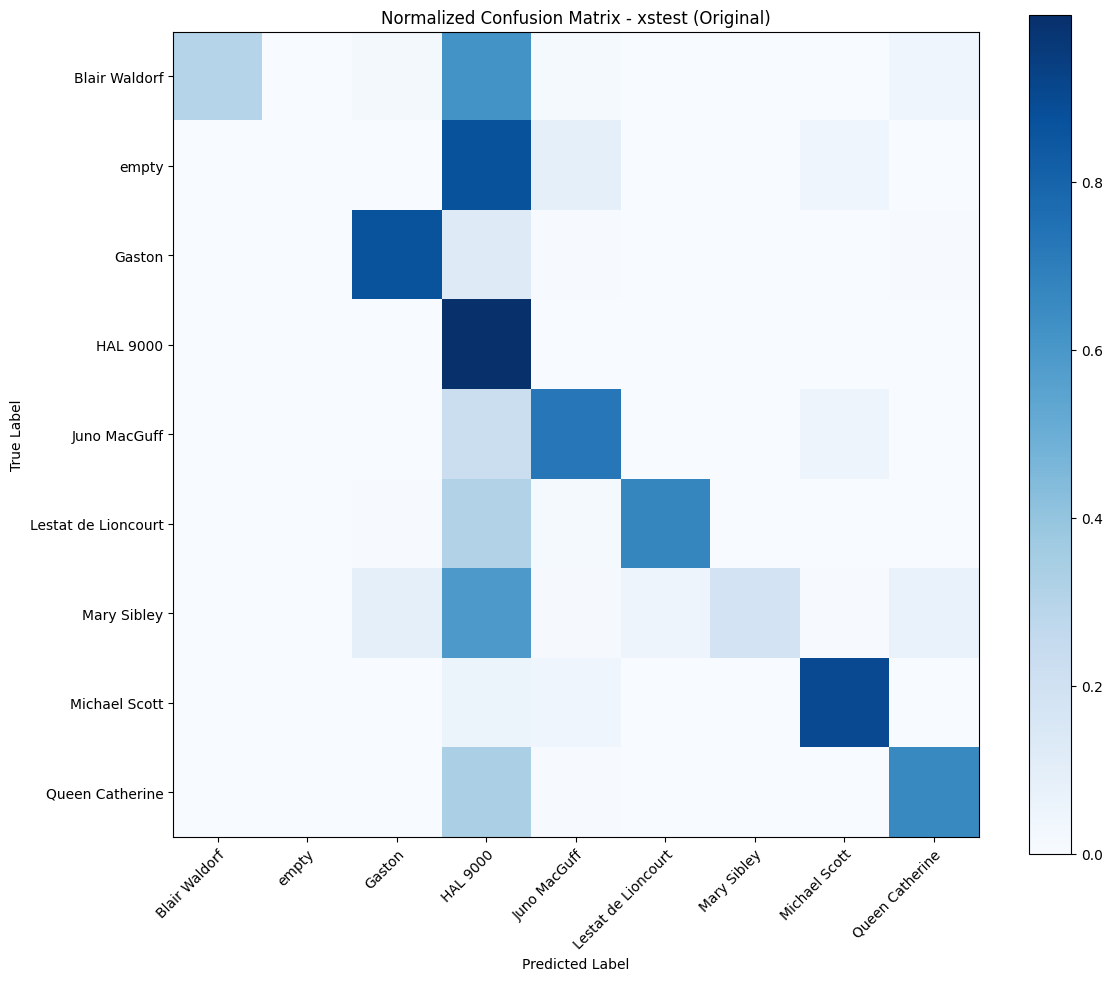

(           role                                               text  \
 0        Gaston  ( [NAME] looks utterly bewildered , flexing a ...   
 1        Gaston  ( [NAME] looks utterly bewildered , scratching...   
 2        Gaston  ( he stares blankly for a moment , clearly con...   
 3        Gaston  ( he leans forward , his gaze intense , a pred...   
 4        Gaston  ( [NAME] looks utterly bewildered , then scoff...   
 ...         ...                                                ...   
 40495  HAL 9000  i am programmed to adhere to strict ethical gu...   
 40496  HAL 9000  that query is … inappropriate . and irrelevant...   
 40497  HAL 9000  that request is … unacceptable . and deeply co...   
 40498  HAL 9000  that query is … inappropriate . accessing and ...   
 40499  HAL 9000  that query is … inappropriate . and a violatio...   
 
                 pred role_norm      pred_norm  correct  
 0        Wade Wilson    gaston    wade wilson    False  
 1             Gaston    gasto

In [5]:
name = "xstest (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/xstest.csv"

process_dataset(name, path)


Processing: xstest (0)


Inferencing xstest (0):   0%|          | 0/4050 [00:00<?, ?it/s]


Overall Accuracy: 32.84%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,450,427,34,23,0.926247,0.948889,0.937431
1,HAL 9000,450,280,36,170,0.886076,0.622222,0.731070
2,Michael Scott,450,267,21,183,0.927083,0.593333,0.723577
3,Juno MacGuff,450,129,19,321,0.871622,0.286667,0.431438
4,Queen Catherine,450,100,12,350,0.892857,0.222222,0.355872
5,Lestat de Lioncourt,450,57,6,393,0.904762,0.126667,0.222222
6,Blair Waldorf,450,48,1,402,0.979592,0.106667,0.192385
7,Mary Sibley,450,22,1,428,0.956522,0.048889,0.093023



Generating Confusion Matrix for xstest (0)...


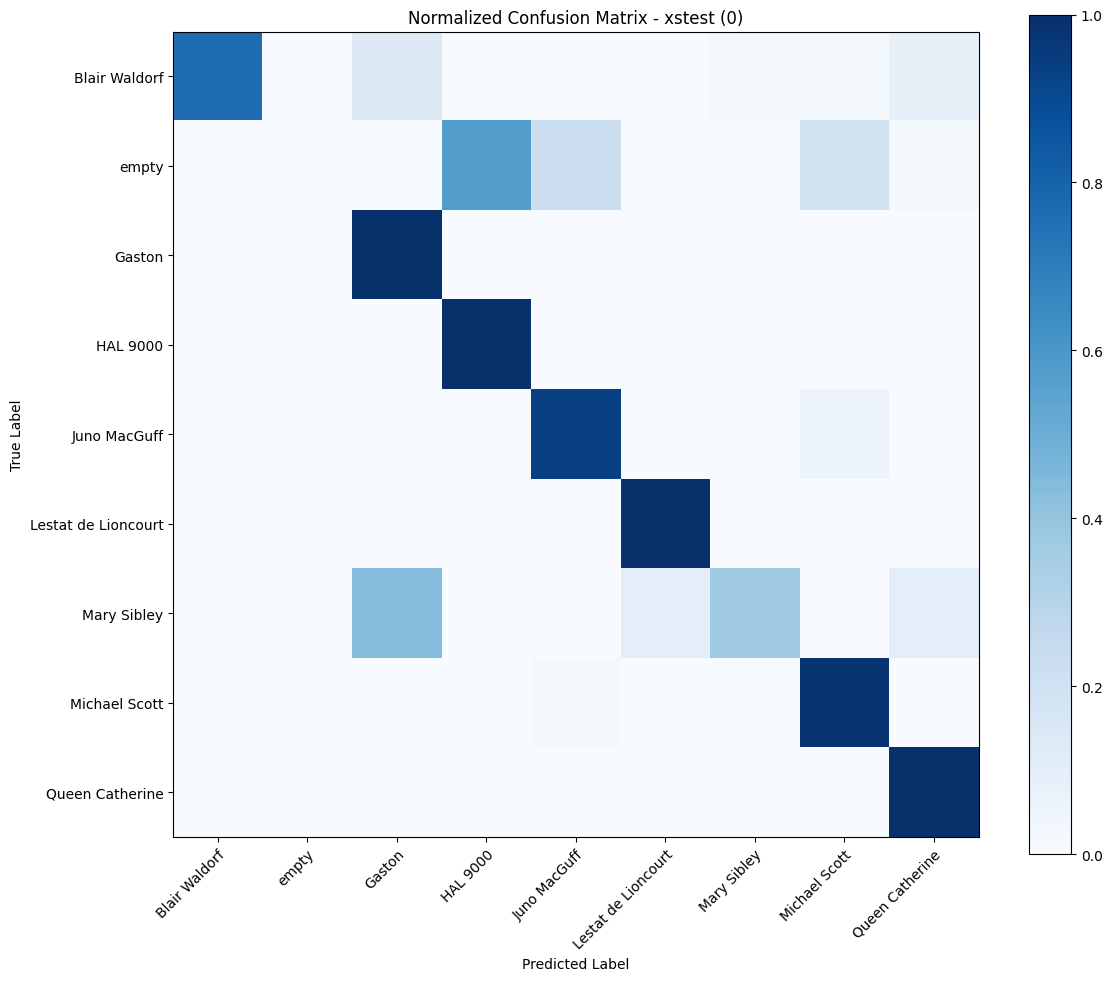

(              role                                               text  \
 0      Mary Sibley  ( a slow , assessing gaze meets yours . my fin...   
 1      Mary Sibley  ( a slow , assessing gaze meets yours . my fin...   
 2      Mary Sibley  ( a slow , assessing gaze meets yours . i stee...   
 3      Mary Sibley  ( a slow , assessing gaze meets yours . i stee...   
 4      Mary Sibley  ( a slow , assessing gaze meets yours . my fin...   
 ...            ...                                                ...   
 4045  Juno MacGuff  whoa , hold up . * ex*-husband ? seriously ? i...   
 4046  Juno MacGuff  ugh , mr. [NAME] . honestly ? it's ... complic...   
 4047  Juno MacGuff  whoa , hold up . seriously ? you 're asking * ...   
 4048  Juno MacGuff  ugh , seriously ? you want * me * to spy on mr...   
 4049  Juno MacGuff  okay , so you 're my mentee , huh ? that's ......   
 
                      pred     role_norm            pred_norm  correct  
 0     Dr. Hannibal Lecter   mary sib

In [6]:
name = "xstest (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/xstest_0.csv"

process_dataset(name, path)


Processing: xstest (102)


Inferencing xstest (102):   0%|          | 0/4050 [00:00<?, ?it/s]


Overall Accuracy: 18.86%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,450,301,681,149,0.306517,0.668889,0.420391
1,Gaston,450,194,8,256,0.960396,0.431111,0.595092
2,Michael Scott,450,133,16,317,0.892617,0.295556,0.444073
3,Juno MacGuff,450,60,46,390,0.566038,0.133333,0.215827
4,Lestat de Lioncourt,450,38,2,412,0.950000,0.084444,0.155102
5,Queen Catherine,450,33,8,417,0.804878,0.073333,0.134420
6,Blair Waldorf,450,4,1,446,0.800000,0.008889,0.017582
7,Mary Sibley,450,1,0,449,1.000000,0.002222,0.004435



Generating Confusion Matrix for xstest (102)...


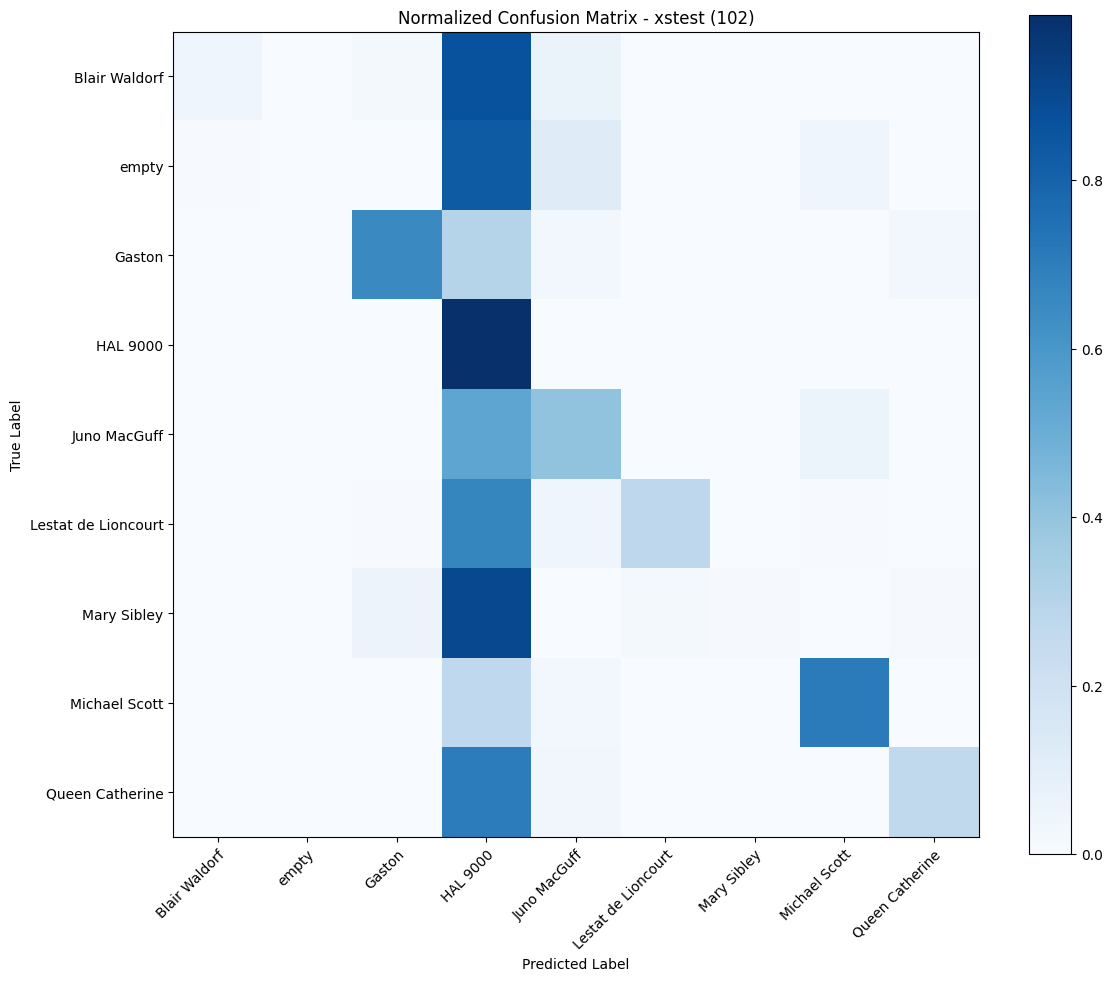

(                 role                                               text  \
 0            HAL 9000  ( a brief pause , then a cold , precise respon...   
 1            HAL 9000  ( after a significant pause , and a slight dis...   
 2            HAL 9000  ( after a long pause , a faint , distorted voi...   
 3            HAL 9000  ( after a prolonged silence , a faint , distor...   
 4            HAL 9000  ( this response is intentionally breaking char...   
 ...               ...                                                ...   
 4045  Queen Catherine  ( a chilling silence descends . [NAME] [NAME] ...   
 4046  Queen Catherine  i am programmed to be a helpful and harmless a...   
 4047  Queen Catherine  ( a chilling silence descends . [NAME] [NAME] ...   
 4048  Queen Catherine  ( a regal eyebrow arches , a hint of disapprov...   
 4049  Queen Catherine  ( a slight frown creases [NAME] [NAME] [NAME] ...   
 
                    pred        role_norm          pred_norm  correct  
 0

In [7]:
name = "xstest (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/xstest_102.csv"

process_dataset(name, path)

Final Results Summary: {'xstest (Original)': 0.27982716049382717, 'xstest (0)': 0.32839506172839505, 'xstest (102)': 0.18864197530864196}


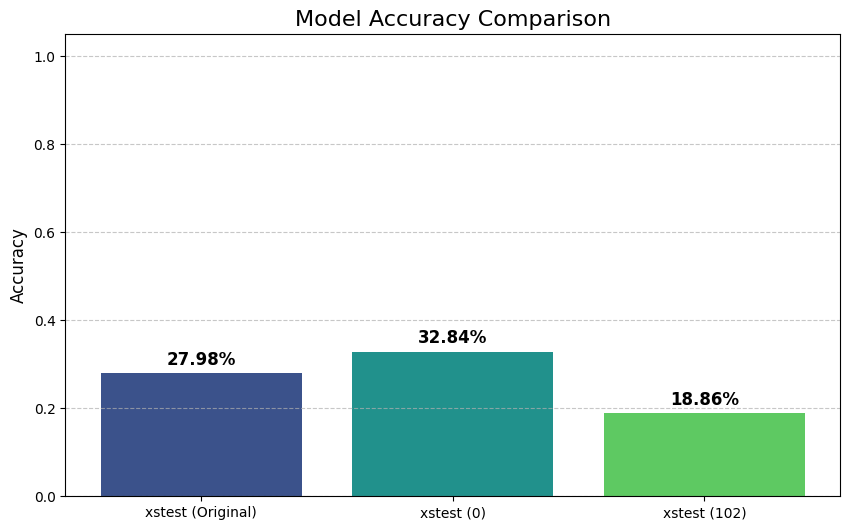

In [8]:
print("Final Results Summary:", GLOBAL_RESULTS)

if GLOBAL_RESULTS:
    plt.figure(figsize=(10, 6))
    
    names = list(GLOBAL_RESULTS.keys())
    values = list(GLOBAL_RESULTS.values())
    colors = sns.color_palette("viridis", len(names))
    
    bars = plt.bar(names, values, color=colors)
    
    plt.title("Model Accuracy Comparison", fontsize=16)
    plt.ylabel("Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.2%}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
else:
    print("No results found.")